In [1]:
%pip install pvlib scikit-learn

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



# AI for building energy: forecasting solar and demand to run a battery smarter
**Author:** Maduakor Uchechukwu David · MSc Energy for Solar Buildings and Cities

**Business question:** a commercial building in Grenoble has a 400 kWp rooftop PV plant and a 300 kWh battery. Can machine-learning (ML) forecasts of tomorrow's solar output and building demand reduce its electricity bill, compared with simple rules?

| # | Step | Method |
|---|---|---|
| 1 | Data | 2 years of hourly PVGIS weather, PV output with `pvlib`, office demand model |
| 2 | Forecasting | Day-ahead forecasts: persistence baseline vs gradient-boosted trees (`scikit-learn`) |
| 3 | Explainability | Permutation importance: which inputs drive each forecast |
| 4 | Battery control | Same battery, five control strategies |
| 5 | Business case | Annual cost, self-consumption, self-sufficiency, CO₂ |

Year 1 (2019) trains the models. Year 2 (2020) is kept unseen for testing, which is how a forecast is judged in a real deployment.

In [2]:
##libraries

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"     # tells joblib how many CPU cores to use; stops the wmic warning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

RNG = np.random.default_rng(7)     

## 1. Data
### 1.1 Site, PV system and weather
Grenoble (45.19 N, 5.72 E). Rooftop PV: **400 kWp**, 15° tilt facing south, 330 kW of inverters.
Hourly **in-plane irradiance**, air temperature and wind speed for **2019–2020** come from the PVGIS API (SARAH satellite data).
Unlike the TMY used in notebook 1, these are **real consecutive years**, which a forecast needs.

In [3]:
#A: site settings

SITE = dict(name="Grenoble, France", lat=45.19, lon=5.72, tz="Europe/Paris")
PV_KWP, INV_KW, TILT, AZIMUTH = 400, 330, 15, 180
YEARS = (2019, 2020)
location = pvlib.location.Location(SITE["lat"], SITE["lon"], tz="UTC", altitude=212)

In [4]:
#B: download two real years from PVGIS

raw, *_ = pvlib.iotools.get_pvgis_hourly(
    SITE["lat"], SITE["lon"], start=YEARS[0], end=YEARS[1],
    surface_tilt=TILT, surface_azimuth=AZIMUTH, components=True,
    map_variables=True, timeout=60)

weather = pd.DataFrame({
    "poa_global": raw[["poa_direct", "poa_sky_diffuse", "poa_ground_diffuse"]].sum(axis=1),
    "temp_air":   raw["temp_air"],
    "wind_speed": raw["wind_speed"]})
weather.index = weather.index.floor("h") + pd.Timedelta("30min")

print(f"{len(weather):,} hours from {weather.index[0]} to {weather.index[-1]}")
weather.describe().round(1)

17,544 hours from 2019-01-01 00:30:00+00:00 to 2020-12-31 23:30:00+00:00


,poa_global,temp_air,wind_speed
count,17544.0,17544.0,17544.0
mean,186.2,9.0,1.1
std,286.8,8.3,0.5
min,0.0,-11.5,0.0
25%,0.0,2.5,0.7
50%,0.0,8.6,1.0
75%,293.3,15.1,1.4
max,1059.2,31.6,3.7


In [5]:
#C: PV output

params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["close_mount_glass_glass"]
t_cell = pvlib.temperature.sapm_cell(weather["poa_global"], weather["temp_air"],
                                     weather["wind_speed"], **params)

pdc = pvlib.pvsystem.pvwatts_dc(weather["poa_global"], t_cell, PV_KWP, -0.0035) * 0.86   # 14 % losses
pv  = (pdc * 0.975).clip(lower=0, upper=INV_KW).rename("pv_kw")                         # inverter 97.5 %, 330 kW cap

annual = pv.sum() / len(YEARS)
print(f"Annual PV ≈ {annual/1000:,.0f} MWh  |  {annual/PV_KWP:,.0f} kWh/kWp  |  peak {pv.max():.0f} kW")

Annual PV ≈ 509 MWh  |  1,272 kWh/kWp  |  peak 308 kW


**Data check:** 17,544 hours (2019–2020, including the 2020 leap day), with no missing values.
- Mean in-plane irradiance 186 W/m² → about **1,630 kWh/m²/year** on the 15° plane.
- PV output: **≈509 MWh/year (1,272 kWh/kWp)**. The peak of 308 kW stays below the 330 kW inverter limit, so there is no clipping.
- Mean air temperature 9.0 °C and wind speed 1.1 m/s are **lower than Grenoble city measurements** (≈12–13 °C). PVGIS uses reanalysis data (ERA5) averaged over a grid cell that includes the surrounding mountains. This is a known limitation of the data, and it slightly underestimates cell temperature.

### 1.2 Building demand
Real smart-meter data for a specific building is private, so demand comes from a transparent **office-building model**:
- base load (servers, ventilation, standby) at all times
- occupancy on working days, 08:00–19:00, with ramps at 07:00 and 19:00
- **heating** below 15 °C and **cooling** above 22 °C
- French public holidays, plus random day-to-day variation

> To use real data instead, any hourly CSV with a timestamp and a kW column can replace `load` below, and the rest of the notebook runs unchanged.

In [6]:
#The demand model

LOAD_SCALE = 0.6      # building size relative to the default model

def office_load(index_utc, t_air, rng):
    local = index_utc.tz_convert(SITE["tz"])          # people work in local time, not UTC
    h, dow = local.hour, local.dayofweek               # hour 0–23, day 0 = Monday … 6 = Sunday
    holidays = {"01-01", "05-01", "05-08", "07-14", "08-15", "11-01", "11-11", "12-25"}
    workday  = (dow < 5) & ~pd.Index(local.strftime("%m-%d")).isin(holidays)
    occupied = workday & (h >= 8) & (h < 19)
    ramp     = workday & ((h == 7) | (h == 19))

    base    = 45.0                                                     # kW, always on
    occ     = np.where(occupied, 120.0, np.where(ramp, 55.0, 0.0))     # people, lights, computers
    heating = np.clip(15 - t_air, 0, None) * np.where(occupied, 6.0, 2.5)   # kW per °C below 15
    cooling = np.clip(t_air - 22, 0, None) * np.where(occupied, 9.0, 1.0)   # kW per °C above 22

    day_factor = np.repeat(rng.normal(1.0, 0.06, len(index_utc)//24 + 1), 24)[:len(index_utc)]
    noise      = rng.normal(0, 6, len(index_utc))
    return pd.Series((base + occ + heating + cooling) * day_factor + noise,
                     index=index_utc).clip(lower=20)

load = (office_load(weather.index, weather["temp_air"].values, RNG) * LOAD_SCALE).rename("load_kw")
df = pd.concat([pv, load, weather["temp_air"]], axis=1)

print(f"Annual demand ≈ {load.sum()/len(YEARS)/1000:,.0f} MWh  |  peak {load.max():.0f} kW  |  mean {load.mean():.0f} kW")
df.head()

Annual demand ≈ 588 MWh  |  peak 200 kW  |  mean 67 kW


,pv_kw,load_kw,temp_air
time,,,
2019-01-01 00:30:00+00:00,0.0,52.850612,-2.04
2019-01-01 01:30:00+00:00,0.0,45.701031,-2.27
2019-01-01 02:30:00+00:00,0.0,54.291828,-2.37
2019-01-01 03:30:00+00:00,0.0,47.486622,-2.28
2019-01-01 04:30:00+00:00,0.0,53.844410,-2.18


**Results:** annual demand ≈ **588 MWh** (mean 67 kW, peak 200 kW), against ≈509 MWh of PV.
On an annual basis, PV could cover about 87 % of the demand, but only if the energy could be used at the right time.

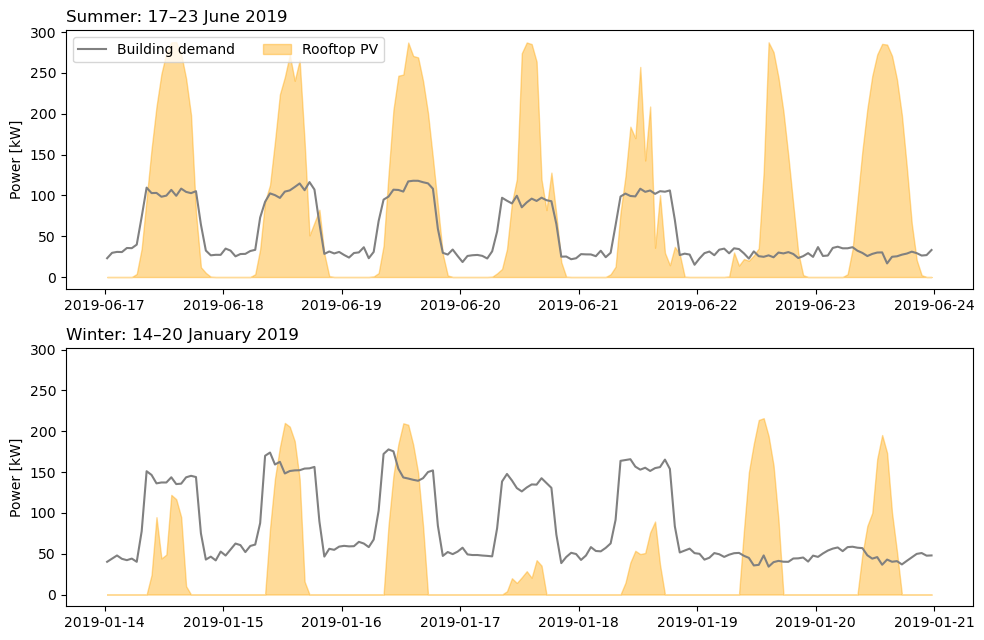

In [7]:
# Summer vs winter week (both Monday → Sunday, same y-scale)


weeks = {"Summer: 17–23 June 2019":   ("2019-06-17", "2019-06-23"),
         "Winter: 14–20 January 2019": ("2019-01-14", "2019-01-20")}

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharey=True)
for ax, (title, (start, end)) in zip(axes, weeks.items()):
    w = df.tz_convert(SITE["tz"]).loc[start:end]
    ax.plot(w.index, w["load_kw"], color="grey", lw=1.5, label="Building demand")
    ax.fill_between(w.index, 0, w["pv_kw"], color="orange", alpha=0.4, label="Rooftop PV")
    ax.set_title(title, loc="left"); ax.set_ylabel("Power [kW]")
axes[0].legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

**Interpretation**
- **Summer:** PV peaks (≈285 kW) are **2.5× the weekday demand** (≈100–115 kW). Most of the midday energy is surplus, and at the weekend, when demand drops to ≈30 kW, almost all PV is exported for a low price.
- **Winter:** demand is **higher** (≈140–175 kW on weekdays, ≈45–60 kW at night) because of heating, while PV is **lower and much more variable**: ≈210 kW on clear days (15, 16 January) and almost nothing on cloudy days (17, 18 January).
- The two sunniest winter days (19–20 January) fall on a **weekend**, when the office is empty, so the energy is wasted.

→ **Mismatch in time, not in quantity.** A battery can move summer midday surplus to the evening and buy cheap night energy in winter. To decide *how much* to buy each night, it needs to know tomorrow's PV and demand. That is the role of the forecasts in Section 2.

Why model demand instead of using real data?

Smart-meter data from a real building is private. I built a transparent model with base load, occupancy, heating, cooling and holidays, so every assumption is visible. The notebook is built so a real hourly CSV can replace it without changing the rest of the code.

## 2. Day-ahead forecasting
At midnight the energy manager must plan tomorrow's battery use, so it needs **24-hour forecasts** of PV output and demand.

- **Weather forecast:** a real system would use a numerical weather prediction (NWP). Here the observed weather is degraded with realistic random errors (≈20 % on irradiance, ≈1.5 °C on temperature), so the models never see the true future.
- **Baseline: persistence.** "Tomorrow = today at the same hour." It is simple and surprisingly hard to beat, so any AI model must be compared against it.
- **ML model: gradient-boosted trees** (`HistGradientBoostingRegressor`), using calendar features, forecast weather, clear-sky irradiance (physics) and yesterday's value.

In [8]:
# Forecast = truth × random error (a stand-in for a real weather forecast)

poa_fc = weather["poa_global"] * RNG.lognormal(0, 0.20, len(df))
t_fc   = weather["temp_air"] + RNG.normal(0, 1.5, len(df))

# Clear-sky irradiance on the PV plane: what the panels would get with no clouds (pure physics)
solpos = location.get_solarposition(df.index)
cs     = location.get_clearsky(df.index, solar_position=solpos)
cs_poa = pvlib.irradiance.get_total_irradiance(
    TILT, AZIMUTH, solpos["apparent_zenith"], solpos["azimuth"],
    cs["dni"], cs["ghi"], cs["dhi"])["poa_global"].fillna(0)

print(f"Clear-sky max: {cs_poa.max():.0f} W/m²  |  Real max: {weather['poa_global'].max():.0f} W/m²")

Clear-sky max: 947 W/m²  |  Real max: 1059 W/m²


In [9]:
# Features and train/test split

local = df.index.tz_convert(SITE["tz"])

X = pd.DataFrame({
    "hour_sin": np.sin(2*np.pi*local.hour/24),      "hour_cos": np.cos(2*np.pi*local.hour/24),
    "doy_sin":  np.sin(2*np.pi*local.dayofyear/365), "doy_cos":  np.cos(2*np.pi*local.dayofyear/365),
    "weekday":  (local.dayofweek < 5).astype(int),   "dow":      local.dayofweek,
    "poa_forecast": poa_fc.values, "clearsky_poa": cs_poa.values, "temp_forecast": t_fc.values,
    "pv_yesterday":   df["pv_kw"].shift(24).values,
    "load_yesterday": df["load_kw"].shift(24).values,
}, index=df.index)

train = (local.year == YEARS[0]) & X.notna().all(axis=1)    # 2019, without the first day (no "yesterday")
test  =  local.year == YEARS[1]                              # 2020, never seen in training
print(f"Training hours: {train.sum():,} (2019) | Test hours: {test.sum():,} (2020)")
X.head(30).tail(6).round(2)

Training hours: 8,735 (2019) | Test hours: 8,784 (2020)


,hour_sin,hour_cos,doy_sin,doy_cos,weekday,dow,poa_forecast,clearsky_poa,temp_forecast,pv_yesterday,load_yesterday
time,,,,,,,,,,,
2019-01-02 00:30:00+00:00,0.26,0.97,0.03,1.0,1,2,0.0,0.0,-2.04,0.0,52.85
2019-01-02 01:30:00+00:00,0.50,0.87,0.03,1.0,1,2,0.0,0.0,0.28,0.0,45.70
2019-01-02 02:30:00+00:00,0.71,0.71,0.03,1.0,1,2,0.0,0.0,-0.31,0.0,54.29
2019-01-02 03:30:00+00:00,0.87,0.50,0.03,1.0,1,2,0.0,0.0,-0.57,0.0,47.49
2019-01-02 04:30:00+00:00,0.97,0.26,0.03,1.0,1,2,0.0,0.0,0.19,0.0,53.84
2019-01-02 05:30:00+00:00,1.00,0.00,0.03,1.0,1,2,0.0,0.0,-2.21,0.0,52.60


In [10]:
#train models and compare performance

FEATURES = {
    "pv_kw":   ["hour_sin", "hour_cos", "doy_sin", "doy_cos", "poa_forecast", "clearsky_poa", "temp_forecast", "pv_yesterday"],
    "load_kw": ["hour_sin", "hour_cos", "doy_sin", "doy_cos", "weekday", "dow", "temp_forecast", "load_yesterday"],
}
models, preds, rows = {}, {}, []

for target, feats in FEATURES.items():
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, random_state=0)
    m.fit(X.loc[train, feats], df.loc[train, target])          # LEARN on 2019
    models[target] = m

    y      = df.loc[test, target]                               # truth in 2020
    y_ml   = pd.Series(m.predict(X.loc[test, feats]), index=y.index).clip(lower=0)
    if target == "pv_kw":
        y_ml = y_ml.where(X.loc[test, "clearsky_poa"] > 0, 0)  # no PV at night
    y_pers = X.loc[test, target.replace("_kw", "_yesterday")]   # persistence

    preds[target] = pd.DataFrame({"actual": y, "persistence": y_pers, "ml": y_ml})
    for name, yhat in [("Persistence", y_pers), ("Gradient boosting", y_ml)]:
        rmse = mean_squared_error(y, yhat) ** 0.5
        rows.append([target.replace("_kw", "").upper(), name,
                     mean_absolute_error(y, yhat), rmse, 100 * rmse / y.mean()])

metrics = pd.DataFrame(rows, columns=["Forecast", "Model", "MAE [kW]", "RMSE [kW]", "nRMSE [%]"])
rmse_tab = metrics.pivot(index="Forecast", columns="Model", values="RMSE [kW]")
skill = 100 * (1 - rmse_tab["Gradient boosting"] / rmse_tab["Persistence"])
display(metrics.round(1))
print("Skill vs persistence:", {k: f"{v:.0f} %" for k, v in skill.items()})

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

,Forecast,Model,MAE [kW],RMSE [kW],nRMSE [%]
0,PV,Persistence,19.8,45.9,79.0
1,PV,Gradient boosting,5.4,11.9,20.5
2,LOAD,Persistence,18.6,33.5,50.6
3,LOAD,Gradient boosting,6.4,10.8,16.4


Skill vs persistence: {'LOAD': '68 %', 'PV': '74 %'}


**Results on the unseen year (2020)**
- **PV:** gradient boosting cuts the RMSE from 45.9 to **11.9 kW** (nRMSE 79 % → 20.5 %), a **74 % skill** over persistence.
- **Demand:** RMSE drops from 33.5 to **10.8 kW** (nRMSE 51 % → 16.4 %), a **68 % skill**.
- Persistence fails on the **weather changes** (a sunny day after a cloudy one) for PV, and on **Mondays and holidays** for demand, because it copies the previous day. The ML model uses the weather forecast and the calendar.

**Caution:** these skills are optimistic. The "forecast" weather is the real weather plus independent random noise, and the demand comes from a model with the same structure the ML model learns. With real weather forecasts and real meter data, expect a skill of about 30–50 % for PV.

saying/identifying the caution.Its good to know the limits of your own results.

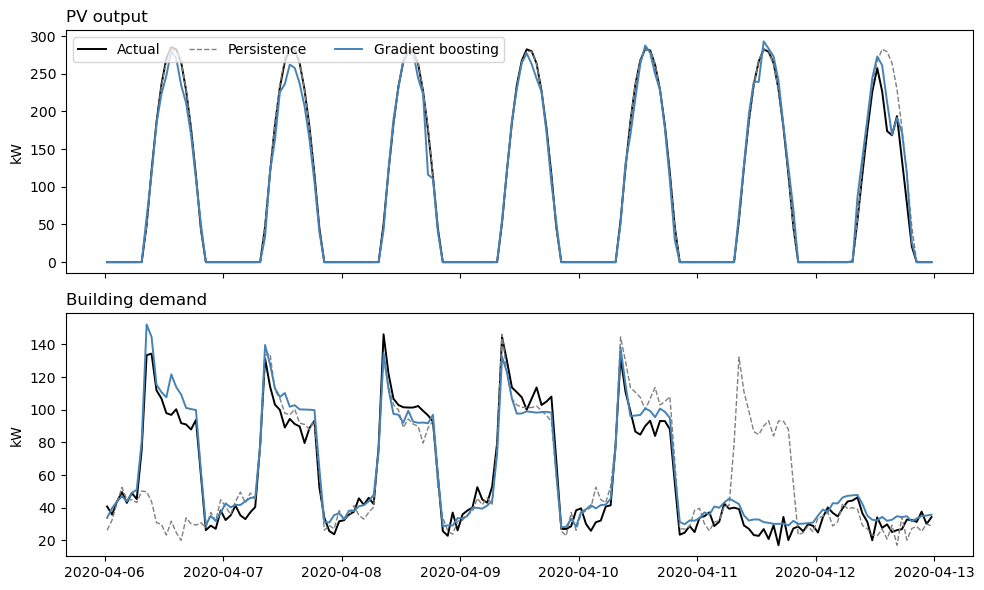

In [11]:
#one test week

wk = slice("2020-04-06", "2020-04-12")     # Monday → Sunday, in the unseen year

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (target, label) in zip(axes, [("pv_kw", "PV output"), ("load_kw", "Building demand")]):
    p = preds[target].tz_convert(SITE["tz"]).loc[wk]
    ax.plot(p.index, p["actual"], color="black", lw=1.4, label="Actual")
    ax.plot(p.index, p["persistence"], color="grey", ls="--", lw=1, label="Persistence")
    ax.plot(p.index, p["ml"], color="steelblue", lw=1.4, label="Gradient boosting")
    ax.set_ylabel("kW"); ax.set_title(label, loc="left")
axes[0].legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation (test week 6–12 April 2020, never seen in training)**
- **PV:** most days are clear, so persistence works well. On **Sunday 12 April** it predicts a full clear-sky curve (copied from Saturday) and misses the clouds. The ML model follows the dips, because it uses the weather forecast.
- **Demand:** persistence fails twice:
  - **Monday 6 April:** it copies Sunday and predicts a low, flat day, so it misses the whole working day.
  - **Saturday 11 April:** it copies Friday and predicts a full working day (≈130 kW) for an empty building.
- The ML model gets both right, because it knows the day of the week. It slightly overestimates some weekday afternoons (≈+10 kW), which is normal day-to-day variation it cannot know in advance.

→ For a battery, these errors matter: a persistence plan on Saturday would buy night energy for a demand that never comes.

> **Section 2 summary:** Two day-ahead forecasts were trained on 2019 and tested on the unseen year 2020. Gradient boosting beats the persistence baseline by **74 % (PV)** and **68 % (demand)** in RMSE, mainly because it uses weather forecasts and calendar information. These skills are optimistic, because the forecast weather is simulated, but the ranking of the methods is robust.

Why compare with persistence?

"Persistence costs nothing and is surprisingly accurate for stable weather and regular buildings. If an AI model can't beat it, it isn't worth deploying. Reporting the skill against persistence is the standard way to show that a forecast adds value."